<a href="https://colab.research.google.com/github/Abdullah-567/Deep-Learning-Tutorials/blob/main/Tutorial_7_Feature_Extraction_vs_FineTuning_PyTorch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tutorial 7 — Feature Extraction vs Fine-Tuning (PyTorch, complete with all tasks)

| Part | Content |
|---|---|
| **0** | Setup, config, data pipeline, model/training helpers |
| **1** | VGG16 *feature extraction* vs ResNet50 *fine-tuning* on CIFAR-10 (Steps 1–5 ported from Keras) |
| **2** | Task: how to improve the fine-tuning results (step-by-step ablation of every hint) |
| **3** | Task: ResNet50 feature extraction vs custom CNN vs VGG16 |
| **4** | Task: fine-tuning VGG16 + feature extraction ResNet50 |
| **5** | Final comparison + conclusions |

**How to run:** Google Colab -> *Runtime -> Change runtime type -> GPU (T4)* -> *Run all*.
On CPU the notebook automatically switches to a tiny "quick run" so it still finishes (accuracy will be low).

**Differences from the Keras tutorial (on purpose):**
* The Keras tutorial used the **test set as validation data**. Here 5,000 training images are held out as a *validation set* (used for early stopping); the **test set is only used once at the end** of each run.
* Keras `layers[-5:]` ~ "last 5 layers". In PyTorch we unfreeze the **last N parameterised layers** (conv / batch-norm / linear).
* Frozen BatchNorm layers are kept in *eval* mode (standard practice for transfer learning).

## Part 0 — Setup

In [ ]:
# Colab already has everything. Uncomment if you run locally:
# !pip install -q torch torchvision matplotlib pandas pillow

In [ ]:
import os, time, random, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
import torchvision
from torchvision import datasets, models, transforms

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed()

DEVICE  = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"          # mixed precision = faster on GPU
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| device:", DEVICE)

# ------------------------------------------------------------------ run size
QUICK_RUN = DEVICE.type == "cpu"         # tiny subset on CPU; set to False to force the full run
N_TRAIN = 4000  if QUICK_RUN else 45000  # (max 45000: 5000 images are held out for validation)
N_VAL   = 1000  if QUICK_RUN else 5000
N_TEST  = 1000  if QUICK_RUN else 10000

BATCH_SIZE        = 64
IMG_SIZE_IMPROVED = 64                   # 224 gives the best accuracy but is ~12x slower
EPOCHS_BASE = 3  if QUICK_RUN else 10    # tutorial value = 10
EPOCHS_LONG = 6  if QUICK_RUN else 25
EPOCHS_TL   = 2  if QUICK_RUN else 5     # epochs per run in Part 7
NUM_WORKERS = 2
print("QUICK_RUN =", QUICK_RUN, "| train/val/test =", N_TRAIN, N_VAL, N_TEST)

torch 2.9.0+cpu | torchvision 0.24.0+cpu | device: cpu
QUICK_RUN = True | train/val/test = 4000 1000 1000


### Data pipeline
*Baseline* (= the tutorial): 32×32 images, pixels scaled to [0, 1] (`ToTensor`).
*Improved*: resize, ImageNet mean/std normalisation (what the pretrained weights expect), optional augmentation.

100%|██████████| 170M/170M [50:34<00:00, 56.2kB/s]


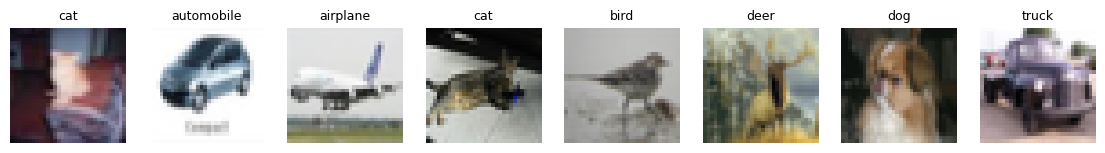

In [ ]:
DATA_DIR = "./data"
CLASSES = ('airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck')
IMAGENET_MEAN, IMAGENET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

# Download once (CIFAR-10, ~170 MB)
datasets.CIFAR10(DATA_DIR, train=True,  download=True)
datasets.CIFAR10(DATA_DIR, train=False, download=True)

# Fixed split -> every experiment sees exactly the same images
_perm     = np.random.RandomState(SEED).permutation(50000)
VAL_IDX   = _perm[:N_VAL]
TRAIN_IDX = _perm[5000:5000 + N_TRAIN]
TEST_IDX  = np.random.RandomState(SEED).permutation(10000)[:N_TEST]

def make_transforms(img_size=32, norm="none", augment=False):
    tr, ev = [], []
    if img_size != 32:
        tr.append(transforms.Resize(img_size)); ev.append(transforms.Resize(img_size))
    if augment:
        tr += [transforms.RandomHorizontalFlip(), transforms.RandomCrop(img_size, padding=img_size // 8)]
    tr.append(transforms.ToTensor()); ev.append(transforms.ToTensor())
    if norm == "imagenet":
        n = transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
        tr.append(n); ev.append(n)
    return transforms.Compose(tr), transforms.Compose(ev)

def get_loaders(img_size=32, norm="none", augment=False, batch_size=BATCH_SIZE):
    tr_t, ev_t = make_transforms(img_size, norm, augment)
    tr_full = datasets.CIFAR10(DATA_DIR, train=True,  download=False, transform=tr_t)
    ev_full = datasets.CIFAR10(DATA_DIR, train=True,  download=False, transform=ev_t)
    te_full = datasets.CIFAR10(DATA_DIR, train=False, download=False, transform=ev_t)
    kw = dict(num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda", persistent_workers=NUM_WORKERS > 0)
    train_loader = DataLoader(Subset(tr_full, TRAIN_IDX), batch_size=batch_size, shuffle=True, drop_last=True, **kw)
    val_loader   = DataLoader(Subset(ev_full, VAL_IDX),   batch_size=256, shuffle=False, **kw)
    test_loader  = DataLoader(Subset(te_full, TEST_IDX),  batch_size=256, shuffle=False, **kw)
    return train_loader, val_loader, test_loader

# quick look at the data
raw = datasets.CIFAR10(DATA_DIR, train=True, download=False)
fig, axes = plt.subplots(1, 8, figsize=(14, 2))
for ax, i in zip(axes, TRAIN_IDX[:8]):
    ax.imshow(raw[i][0]); ax.set_title(CLASSES[raw[i][1]], fontsize=9); ax.axis("off")
plt.show()

### Models
* `build_model(arch, ...)` loads an **ImageNet-pretrained** torchvision model and swaps its classifier for the tutorial's head:
  `Flatten → Dense(512, ReLU) → Dense(10)` (plus optional dropout / a deeper BN head for the improvement task).
* `configure_trainable(model, unfreeze)`:  `0` = **feature extraction** (only the new head trains),
  `N` = **fine-tuning** (head + last *N* conv/BN layers), `"all"` = full fine-tuning.
* `CustomCNN` = small network trained **from scratch** (for the comparison in Part 3).

In [ ]:
def make_head(in_features, hidden=512, dropout=0.0, n_classes=10, head_type="simple"):
    if head_type == "simple":        # tutorial: Dense(512, relu) -> Dense(10)
        return nn.Sequential(nn.Linear(in_features, hidden), nn.ReLU(inplace=True),
                             nn.Dropout(dropout), nn.Linear(hidden, n_classes))
    if head_type == "bn_deep":       # "different layers": deeper head with BatchNorm
        return nn.Sequential(nn.Linear(in_features, 1024), nn.BatchNorm1d(1024), nn.ReLU(inplace=True), nn.Dropout(dropout),
                             nn.Linear(1024, 256), nn.BatchNorm1d(256), nn.ReLU(inplace=True), nn.Dropout(dropout),
                             nn.Linear(256, n_classes))
    raise ValueError(head_type)

# arch -> (name of the classifier attribute, #features entering it)
ARCH_INFO = {"vgg16": ("classifier", 512), "alexnet": ("classifier", 256),
             "resnet50": ("fc", 2048), "resnet101": ("fc", 2048), "mobilenet_v2": ("classifier", 1280)}

def build_model(arch, pretrained=True, dropout=0.0, head_type="simple"):
    model = models.get_model(arch, weights="IMAGENET1K_V1" if pretrained else None)
    attr, in_f = ARCH_INFO[arch]
    if arch in ("vgg16", "alexnet"):
        model.avgpool = nn.AdaptiveAvgPool2d(1)      # like Keras Flatten on the last conv map (works for any input size)
    setattr(model, attr, make_head(in_f, dropout=dropout, head_type=head_type))
    model._head_attr = attr
    return model

class CustomCNN(nn.Module):
    """Small VGG-style CNN trained from scratch."""
    def __init__(self, n_classes=10, dropout=0.0):
        super().__init__()
        def block(i, o):
            return nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                                 nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                                 nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128), nn.AdaptiveAvgPool2d(1), nn.Flatten())
        self.classifier = make_head(128, dropout=dropout)
        self._head_attr = "classifier"
    def forward(self, x):
        return self.classifier(self.features(x))

def head_of(model):
    return getattr(model, model._head_attr)

def backbone_layers(model):
    """Leaf layers that own parameters (conv / BN / linear), in forward order, excluding the new head."""
    head_ids = {id(m) for m in head_of(model).modules()}
    return [m for m in model.modules()
            if not list(m.children()) and list(m.parameters(recurse=False)) and id(m) not in head_ids]

def configure_trainable(model, unfreeze=0):
    for p in model.parameters(): p.requires_grad = False
    for p in head_of(model).parameters(): p.requires_grad = True
    layers = backbone_layers(model)
    chosen = layers if unfreeze == "all" else (layers[-unfreeze:] if unfreeze else [])
    for m in chosen:
        for p in m.parameters(): p.requires_grad = True

def set_train_mode(model):
    """model.train(), but BatchNorm layers whose weights are frozen stay in eval mode."""
    model.train()
    for m in model.modules():
        if isinstance(m, nn.modules.batchnorm._BatchNorm):
            ps = list(m.parameters(recurse=False))
            if ps and not any(p.requires_grad for p in ps):
                m.eval()

def trainable_param_groups(model, lr_head, lr_backbone):
    head_ids = {id(p) for p in head_of(model).parameters()}
    head_p = [p for p in model.parameters() if id(p) in head_ids]
    bb_p   = [p for p in model.parameters() if p.requires_grad and id(p) not in head_ids]
    groups = [{"params": head_p, "lr": lr_head}]
    if bb_p: groups.append({"params": bb_p, "lr": lr_backbone})
    return groups

# sanity check: how many layers does each strategy train?
_m = build_model("resnet50", pretrained=False)
for n in (0, 5, 20, 58, "all"):
    configure_trainable(_m, n)
    print(f"ResNet50 unfreeze={n!s:>3}: trainable params = {sum(p.numel() for p in _m.parameters() if p.requires_grad):>11,}")
del _m

ResNet50 unfreeze=  0: trainable params =   1,054,218
ResNet50 unfreeze=  5: trainable params =   4,468,234
ResNet50 unfreeze= 20: trainable params =  16,018,954
ResNet50 unfreeze= 58: trainable params =  23,117,322
ResNet50 unfreeze=all: trainable params =  24,562,250


### Training / evaluation helpers (with early stopping, LR scheduler, label smoothing, AMP)

In [ ]:
def evaluate(model, loader):
    model.eval()
    crit = nn.CrossEntropyLoss(reduction="sum")
    tot, correct, n = 0.0, 0, 0
    with torch.no_grad(), torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
        for x, y in loader:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            out = model(x).float()
            tot += crit(out, y).item(); correct += (out.argmax(1) == y).sum().item(); n += y.numel()
    return tot / n, correct / n

def fit(model, train_loader, val_loader, cfg):
    model.to(DEVICE)
    opt  = torch.optim.AdamW(trainable_param_groups(model, cfg["lr_head"], cfg["lr_backbone"]),
                             weight_decay=cfg["weight_decay"])
    sched = None
    if cfg["scheduler"] == "cosine":
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cfg["epochs"] * len(train_loader))
    crit   = nn.CrossEntropyLoss(label_smoothing=cfg["label_smoothing"])
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val, best_state, bad = -1.0, None, 0

    for epoch in range(1, cfg["epochs"] + 1):
        set_train_mode(model)
        t0, run_loss, correct, n = time.time(), 0.0, 0, 0
        for x, y in train_loader:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                out = model(x).float()
                loss = crit(out, y)
            scaler.scale(loss).backward()
            scaler.step(opt); scaler.update()
            if sched: sched.step()
            run_loss += loss.item() * y.size(0); correct += (out.argmax(1) == y).sum().item(); n += y.size(0)
        vl, va = evaluate(model, val_loader)
        hist["train_loss"].append(run_loss / n); hist["train_acc"].append(correct / n)
        hist["val_loss"].append(vl);             hist["val_acc"].append(va)
        print(f"  epoch {epoch:>2}/{cfg['epochs']}  train loss {run_loss/n:.3f} acc {correct/n:.3f} | "
              f"val loss {vl:.3f} acc {va:.3f} | {time.time()-t0:.0f}s")
        if cfg["patience"]:                                   # early stopping on validation accuracy
            if va > best_val + 1e-4:
                best_val, bad = va, 0
                best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            else:
                bad += 1
                if bad >= cfg["patience"]:
                    print(f"  early stopping at epoch {epoch} (best val acc {best_val:.3f})"); break
    if best_state is not None:
        model.load_state_dict(best_state)                     # restore best weights
    return hist

# Default recipe = the Keras tutorial (Adam 1e-3, 32x32 pixels in [0,1], no augmentation, no regularisation)
BASE_CFG = dict(img_size=32, norm="none", augment=False, dropout=0.0, head_type="simple",
                epochs=EPOCHS_BASE, lr_head=1e-3, lr_backbone=1e-3, weight_decay=0.0,
                label_smoothing=0.0, scheduler=None, patience=None, unfreeze=5)

RESULTS, BEST = [], {"acc": -1.0}

def run_experiment(name, arch, mode, **overrides):
    """mode: 'fe' = feature extraction | 'ft' = fine-tuning (last cfg['unfreeze'] layers) | 'scratch' = custom CNN"""
    cfg = {**BASE_CFG, **overrides}
    set_seed()
    print(f"\n=== {name}  [{arch} | {mode} | {cfg['img_size']}px | unfreeze={cfg['unfreeze'] if mode=='ft' else '-'} | "
          f"lr {cfg['lr_head']:g}/{cfg['lr_backbone']:g} | epochs {cfg['epochs']}]")
    train_loader, val_loader, test_loader = get_loaders(cfg["img_size"], cfg["norm"], cfg["augment"])
    if mode == "scratch":
        model = CustomCNN(dropout=cfg["dropout"])
    else:
        model = build_model(arch, True, cfg["dropout"], cfg["head_type"])
        configure_trainable(model, cfg["unfreeze"] if mode == "ft" else 0)
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    t0 = time.time()
    hist = fit(model, train_loader, val_loader, cfg)
    secs = time.time() - t0
    test_loss, test_acc = evaluate(model, test_loader)
    print(f"  >> {name} Test Accuracy: {test_acc * 100:.2f}%  (trainable params {trainable:,}, {secs:.0f}s)")
    res = dict(name=name, arch=arch, mode=mode, img_size=cfg["img_size"], epochs_run=len(hist["val_acc"]),
               trainable_params=trainable, best_val_acc=max(hist["val_acc"]), test_acc=test_acc,
               test_loss=test_loss, train_time_s=secs, history=hist)
    RESULTS.append(res)
    if test_acc > BEST["acc"]:                                # keep the best model for the prediction demo at the end
        BEST.update(acc=test_acc, name=name, cfg=cfg, model=model.cpu())
    else:
        del model
    if DEVICE.type == "cuda": torch.cuda.empty_cache()
    return res

def plot_histories(results, title=""):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    for i, r in enumerate(results):
        h, c = r["history"], f"C{i}"
        ep = range(1, len(h["val_acc"]) + 1)
        ax[0].plot(ep, h["train_acc"], "--", color=c, alpha=.6); ax[0].plot(ep, h["val_acc"], color=c, label=r["name"])
        ax[1].plot(ep, h["train_loss"], "--", color=c, alpha=.6); ax[1].plot(ep, h["val_loss"], color=c)
    ax[0].set_title("Accuracy (dashed = train, solid = validation)"); ax[1].set_title("Loss (dashed = train, solid = validation)")
    for a in ax: a.set_xlabel("epoch"); a.grid(alpha=.3)
    ax[0].legend(fontsize=8); fig.suptitle(title); plt.tight_layout(); plt.show()

def results_table(results):
    cols = ["name", "arch", "mode", "img_size", "epochs_run", "trainable_params", "best_val_acc", "test_acc", "train_time_s"]
    df = pd.DataFrame([{c: r[c] for c in cols} for r in results])
    df["test_acc"] = (df["test_acc"] * 100).round(2); df["best_val_acc"] = (df["best_val_acc"] * 100).round(2)
    df["train_time_s"] = df["train_time_s"].round(0).astype(int)
    return df

## Part 1 — Tutorial 7: Feature Extraction (VGG16) vs Fine-Tuning (ResNet50)

PyTorch version of Steps 1–5 of the tutorial (the imports = Step 1, data = Step 2 are in Part 0).

**Step 3a – Feature extraction with VGG16:** load ImageNet weights, **freeze every layer**, train only the new `Dense(512) → Dense(10)` head.

In [ ]:
res_vgg_fe_base = run_experiment("VGG16 feature extraction (tutorial)", "vgg16", "fe")   # Adam 1e-3, only the head trains


=== VGG16 feature extraction (tutorial)  [vgg16 | fe | 32px | unfreeze=- | lr 0.001/0.001 | epochs 3]
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:02<00:00, 245MB/s]


  epoch  1/3  train loss 1.569 acc 0.450 | val loss 1.328 acc 0.540 | 18s
  epoch  2/3  train loss 1.153 acc 0.612 | val loss 1.282 acc 0.556 | 18s
  epoch  3/3  train loss 1.016 acc 0.646 | val loss 1.255 acc 0.562 | 17s
  >> VGG16 feature extraction (tutorial) Test Accuracy: 54.90%  (trainable params 267,786, 53s)


**Step 3b – Fine-tuning with ResNet50:** load ImageNet weights, freeze everything, add the new head, then **unfreeze the last 5 layers** and train with a small learning rate (`Adam(1e-5)`, exactly as in the tutorial).

In [ ]:
res_r50_ft_base = run_experiment("ResNet50 fine-tuning (tutorial)", "resnet50", "ft",
                                 unfreeze=5, lr_head=1e-5, lr_backbone=1e-5)


=== ResNet50 fine-tuning (tutorial)  [resnet50 | ft | 32px | unfreeze=5 | lr 1e-05/1e-05 | epochs 3]
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 265MB/s]


  epoch  1/3  train loss 2.233 acc 0.206 | val loss 2.154 acc 0.300 | 19s
  epoch  2/3  train loss 2.058 acc 0.372 | val loss 2.002 acc 0.397 | 18s
  epoch  3/3  train loss 1.901 acc 0.435 | val loss 1.876 acc 0.450 | 18s
  >> ResNet50 fine-tuning (tutorial) Test Accuracy: 39.90%  (trainable params 4,468,234, 55s)


**Step 4 & 5 – Evaluate and compare** (both models were evaluated on the held-out test set inside `run_experiment`).

Feature Extraction Accuracy: 54.90%
Fine-Tuning Accuracy: 39.90%


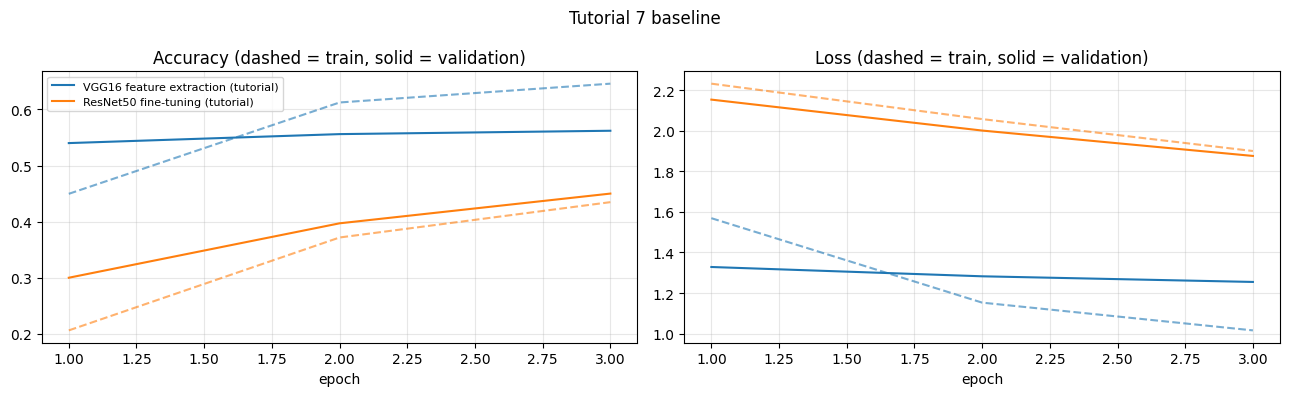

,name,arch,mode,img_size,epochs_run,trainable_params,best_val_acc,test_acc,train_time_s
0,VGG16 feature extraction (tutorial),vgg16,fe,32,3,267786,56.2,54.9,53
1,ResNet50 fine-tuning (tutorial),resnet50,ft,32,3,4468234,45.0,39.9,55


In [ ]:
print(f"Feature Extraction Accuracy: {res_vgg_fe_base['test_acc'] * 100:.2f}%")
print(f"Fine-Tuning Accuracy: {res_r50_ft_base['test_acc'] * 100:.2f}%")
plot_histories([res_vgg_fe_base, res_r50_ft_base], "Tutorial 7 baseline")
results_table([res_vgg_fe_base, res_r50_ft_base])

## Part 2 — Task: How would you improve the fine-tuning results?

The tutorial's fine-tuning recipe is deliberately weak (tiny LR of 1e-5 on the new head too, 32×32 un-normalised inputs, only 5 layers unfrozen, no regularisation).
We add the hints **one after another (cumulatively)** so you can see what each change buys:

| Step | Change | Hint covered |
|---|---|---|
| S1 | head LR 1e-3, backbone LR 1e-4 | *Changing learning rate* |
| S2 | 64×64 inputs + ImageNet mean/std normalisation | *Preprocessing formatting* |
| S3 | augmentation + dropout 0.5 + weight decay + label smoothing | *Prevent overfitting* |
| S4 | unfreeze 58 layers (≈ ResNet `layer3` + `layer4`) | *Unfreeze more layers* |
| S5 | deeper head with BatchNorm | *Different layers* |
| S6 | 25 epochs + cosine LR schedule + early stopping (patience 4) | *Number of epochs, Early stopping* |

In [ ]:
STEPS = [
    ("S1 + learning rate",            dict(lr_head=1e-3, lr_backbone=1e-4)),
    ("S2 + preprocessing",            dict(img_size=IMG_SIZE_IMPROVED, norm="imagenet")),
    ("S3 + regularisation",           dict(augment=True, dropout=0.5, weight_decay=1e-2, label_smoothing=0.1)),
    ("S4 + unfreeze more layers",     dict(unfreeze=58)),
    ("S5 + different head layers",    dict(head_type="bn_deep")),
    ("S6 + epochs/cosine/early stop", dict(epochs=EPOCHS_LONG, scheduler="cosine", patience=4)),
]
cum = dict(unfreeze=5, lr_head=1e-5, lr_backbone=1e-5)      # S0 = tutorial recipe
ft_ablation = [res_r50_ft_base]
for label, change in STEPS:
    cum.update(change)
    ft_ablation.append(run_experiment(f"ResNet50 FT {label}", "resnet50", "ft", **cum))


=== ResNet50 FT S1 + learning rate  [resnet50 | ft | 32px | unfreeze=5 | lr 0.001/0.0001 | epochs 3]
  epoch  1/3  train loss 1.700 acc 0.414 | val loss 1.481 acc 0.489 | 19s
  epoch  2/3  train loss 1.148 acc 0.602 | val loss 1.438 acc 0.527 | 18s
  epoch  3/3  train loss 0.841 acc 0.716 | val loss 1.555 acc 0.506 | 18s
  >> ResNet50 FT S1 + learning rate Test Accuracy: 48.00%  (trainable params 4,468,234, 55s)

=== ResNet50 FT S2 + preprocessing  [resnet50 | ft | 64px | unfreeze=5 | lr 0.001/0.0001 | epochs 3]
  epoch  1/3  train loss 0.980 acc 0.675 | val loss 0.733 acc 0.751 | 36s
  epoch  2/3  train loss 0.447 acc 0.847 | val loss 0.747 acc 0.765 | 33s
  epoch  3/3  train loss 0.259 acc 0.908 | val loss 0.884 acc 0.746 | 32s
  >> ResNet50 FT S2 + preprocessing Test Accuracy: 74.20%  (trainable params 4,468,234, 100s)

=== ResNet50 FT S3 + regularisation  [resnet50 | ft | 64px | unfreeze=5 | lr 0.001/0.0001 | epochs 3]
  epoch  1/3  train loss 1.581 acc 0.526 | val loss 0.908 acc 

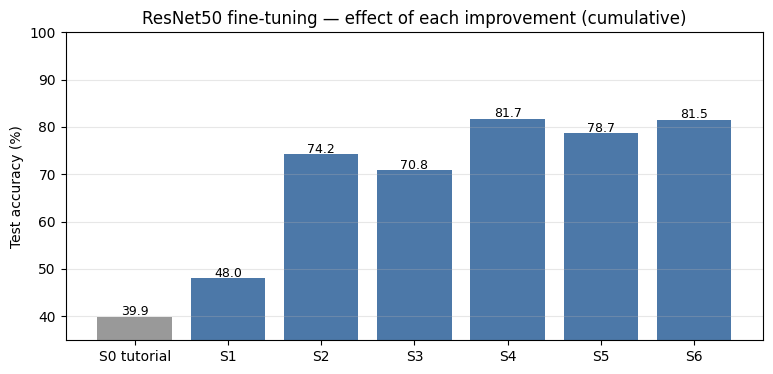

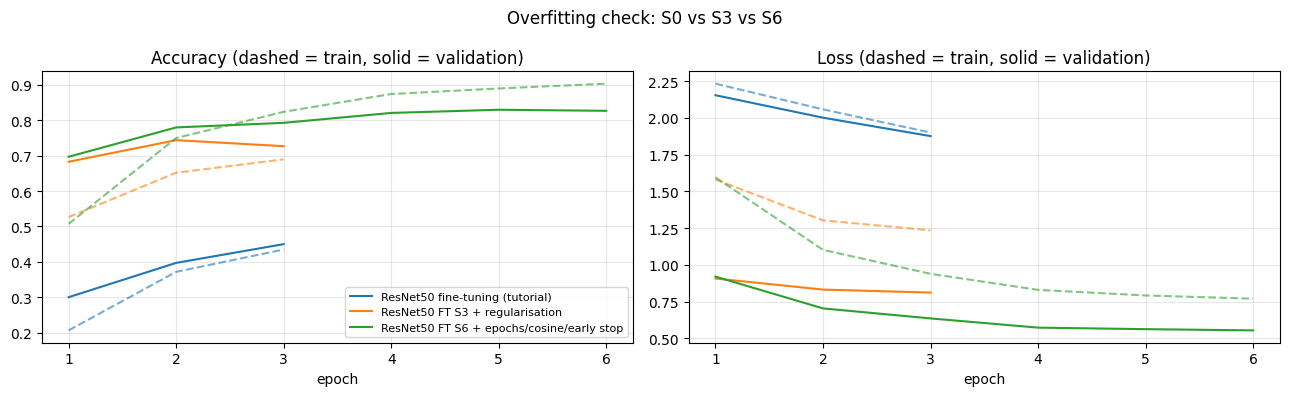

,name,arch,mode,img_size,epochs_run,trainable_params,best_val_acc,test_acc,train_time_s
0,ResNet50 fine-tuning (tutorial),resnet50,ft,32,3,4468234,45.0,39.9,55
1,ResNet50 FT S1 + learning rate,resnet50,ft,32,3,4468234,52.7,48.0,55
2,ResNet50 FT S2 + preprocessing,resnet50,ft,64,3,4468234,76.5,74.2,100
3,ResNet50 FT S3 + regularisation,resnet50,ft,64,3,4468234,74.4,70.8,103
4,ResNet50 FT S4 + unfreeze more layers,resnet50,ft,64,3,23117322,82.0,81.7,197
5,ResNet50 FT S5 + different head layers,resnet50,ft,64,3,24428810,80.2,78.7,201
6,ResNet50 FT S6 + epochs/cosine/early stop,resnet50,ft,64,6,24428810,83.0,81.5,388


In [ ]:
labels = ["S0 tutorial"] + [s[0].split(" ")[0] for s in STEPS]
accs = [r["test_acc"] * 100 for r in ft_ablation]
plt.figure(figsize=(9, 4))
bars = plt.bar(labels, accs, color=["#999"] + ["#4C78A8"] * len(STEPS))
for b, a in zip(bars, accs): plt.text(b.get_x() + b.get_width() / 2, a + .3, f"{a:.1f}", ha="center", fontsize=9)
plt.ylabel("Test accuracy (%)"); plt.title("ResNet50 fine-tuning — effect of each improvement (cumulative)")
plt.ylim(min(accs) - 5, 100); plt.grid(axis="y", alpha=.3); plt.show()

plot_histories([ft_ablation[0], ft_ablation[3], ft_ablation[-1]], "Overfitting check: S0 vs S3 vs S6")
results_table(ft_ablation)

## Part 3 — Task: Feature extraction with ResNet50 vs custom model vs VGG16

All three models are compared under the **same** data settings, first with the tutorial's settings (32×32, pixels in [0,1]) and then with improved preprocessing (64×64 + ImageNet normalisation).
The *custom model* is a small 6-conv CNN trained from scratch.

In [ ]:
imp_pre = dict(img_size=IMG_SIZE_IMPROVED, norm="imagenet")
cmp_tut = [run_experiment("Custom CNN (scratch) [32px]", "custom", "scratch"),
           res_vgg_fe_base,
           run_experiment("ResNet50 feature extraction [32px]", "resnet50", "fe")]
cmp_imp = [run_experiment(f"Custom CNN (scratch) [{IMG_SIZE_IMPROVED}px]", "custom", "scratch", **imp_pre),
           run_experiment(f"VGG16 feature extraction [{IMG_SIZE_IMPROVED}px]", "vgg16", "fe", **imp_pre),
           run_experiment(f"ResNet50 feature extraction [{IMG_SIZE_IMPROVED}px]", "resnet50", "fe", **imp_pre)]
res_r50_fe_tut = cmp_tut[2]


=== Custom CNN (scratch) [32px]  [custom | scratch | 32px | unfreeze=- | lr 0.001/0.001 | epochs 3]
  epoch  1/3  train loss 1.827 acc 0.307 | val loss 2.508 acc 0.199 | 10s
  epoch  2/3  train loss 1.542 acc 0.431 | val loss 1.989 acc 0.337 | 9s
  epoch  3/3  train loss 1.376 acc 0.498 | val loss 1.666 acc 0.408 | 9s
  >> Custom CNN (scratch) [32px] Test Accuracy: 40.40%  (trainable params 358,634, 29s)

=== ResNet50 feature extraction [32px]  [resnet50 | fe | 32px | unfreeze=- | lr 0.001/0.001 | epochs 3]
  epoch  1/3  train loss 1.576 acc 0.442 | val loss 1.396 acc 0.501 | 13s
  epoch  2/3  train loss 1.182 acc 0.585 | val loss 1.304 acc 0.545 | 11s
  epoch  3/3  train loss 1.028 acc 0.645 | val loss 1.320 acc 0.540 | 11s
  >> ResNet50 feature extraction [32px] Test Accuracy: 52.90%  (trainable params 1,054,218, 36s)

=== Custom CNN (scratch) [64px]  [custom | scratch | 64px | unfreeze=- | lr 0.001/0.001 | epochs 3]
  epoch  1/3  train loss 1.914 acc 0.266 | val loss 1.852 acc 0.28

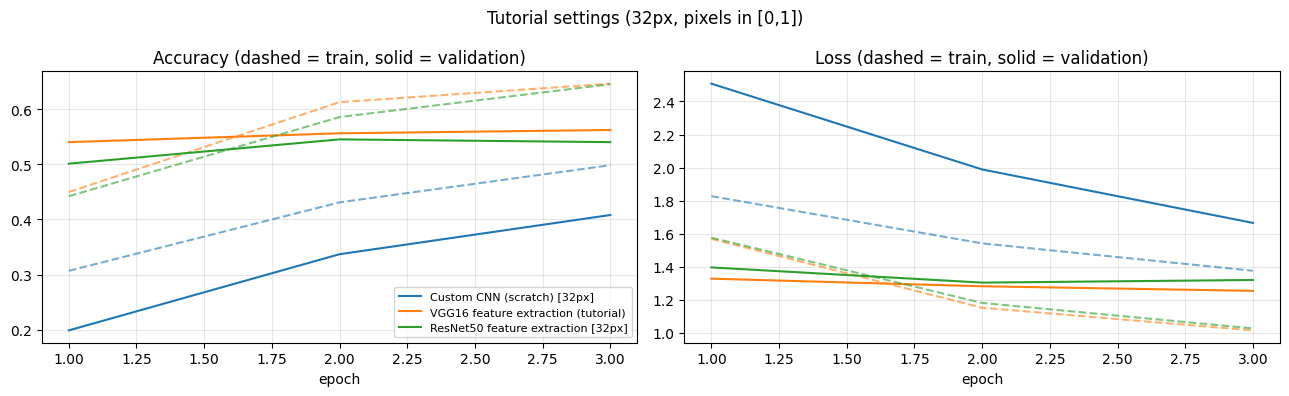

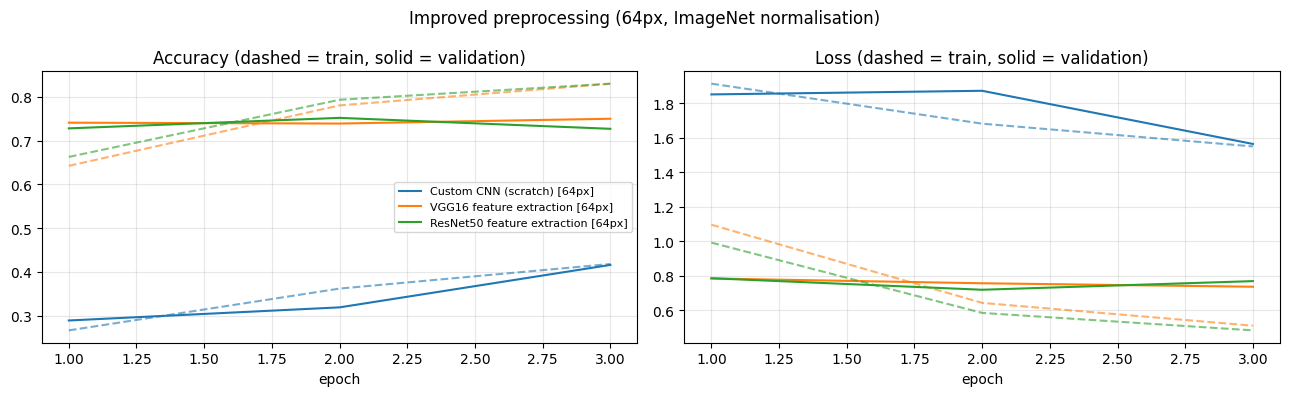

,name,arch,mode,img_size,epochs_run,trainable_params,best_val_acc,test_acc,train_time_s
0,Custom CNN (scratch) [32px],custom,scratch,32,3,358634,40.8,40.4,29
1,VGG16 feature extraction (tutorial),vgg16,fe,32,3,267786,56.2,54.9,53
2,ResNet50 feature extraction [32px],resnet50,fe,32,3,1054218,54.5,52.9,36
3,Custom CNN (scratch) [64px],custom,scratch,64,3,358634,41.6,42.1,109
4,VGG16 feature extraction [64px],vgg16,fe,64,3,267786,75.0,71.0,181
5,ResNet50 feature extraction [64px],resnet50,fe,64,3,1054218,75.2,71.2,80


In [ ]:
plot_histories(cmp_tut, "Tutorial settings (32px, pixels in [0,1])")
plot_histories(cmp_imp, f"Improved preprocessing ({IMG_SIZE_IMPROVED}px, ImageNet normalisation)")
results_table(cmp_tut + cmp_imp)

## Part 4 — Task: Fine-tuning with VGG16 and feature extraction with ResNet50

We run the full 2×2 grid **{VGG16, ResNet50} × {feature extraction, fine-tuning}**, each under (a) the tutorial recipe and (b) an improved recipe
(64px + ImageNet norm + augmentation + dropout + weight decay + label smoothing + deeper head + cosine LR + early stopping).

In [ ]:
for v in ["IMG_SIZE_IMPROVED", "EPOCHS_LONG", "res_r50_fe_tut", "ft_ablation", "res_vgg_fe_base", "res_r50_ft_base"]:
    assert v in globals(), f"Run the earlier cell that defines {v} first"

In [ ]:
IMPROVED = dict(img_size=IMG_SIZE_IMPROVED, norm="imagenet", augment=True, dropout=0.5, weight_decay=1e-2,
                label_smoothing=0.1, head_type="bn_deep", epochs=EPOCHS_LONG, scheduler="cosine", patience=4)

# --- tutorial recipe
res_vgg_ft_base = run_experiment("VGG16 fine-tuning (tutorial recipe)", "vgg16", "ft",
                                 unfreeze=5, lr_head=1e-5, lr_backbone=1e-5)
# (ResNet50 FE with tutorial recipe = res_r50_fe_tut, ResNet50 FT = res_r50_ft_base)

# --- improved recipe
res_vgg_fe_imp = run_experiment("VGG16 feature extraction (improved)", "vgg16", "fe", lr_head=1e-3, **IMPROVED)
res_vgg_ft_imp = run_experiment("VGG16 fine-tuning (improved)", "vgg16", "ft", unfreeze=6,
                                lr_head=1e-3, lr_backbone=5e-5, **IMPROVED)       # last 2 conv blocks
res_r50_fe_imp = run_experiment("ResNet50 feature extraction (improved)", "resnet50", "fe", lr_head=1e-3, **IMPROVED)
res_r50_ft_imp = ft_ablation[-1]                                                  # S6 from Part 2


=== VGG16 fine-tuning (tutorial recipe)  [vgg16 | ft | 32px | unfreeze=5 | lr 1e-05/1e-05 | epochs 3]
  epoch  1/3  train loss 2.195 acc 0.243 | val loss 2.026 acc 0.324 | 42s
  epoch  2/3  train loss 1.651 acc 0.460 | val loss 1.331 acc 0.546 | 39s
  epoch  3/3  train loss 1.149 acc 0.599 | val loss 1.089 acc 0.625 | 39s
  >> VGG16 fine-tuning (tutorial recipe) Test Accuracy: 57.30%  (trainable params 12,066,826, 120s)

=== VGG16 feature extraction (improved)  [vgg16 | fe | 64px | unfreeze=- | lr 0.001/0.001 | epochs 6]
  epoch  1/6  train loss 1.631 acc 0.507 | val loss 0.990 acc 0.685 | 62s
  epoch  2/6  train loss 1.357 acc 0.625 | val loss 0.901 acc 0.697 | 62s
  epoch  3/6  train loss 1.287 acc 0.650 | val loss 0.890 acc 0.703 | 63s
  epoch  4/6  train loss 1.237 acc 0.681 | val loss 0.861 acc 0.714 | 64s
  epoch  5/6  train loss 1.216 acc 0.693 | val loss 0.849 acc 0.716 | 64s
  epoch  6/6  train loss 1.220 acc 0.693 | val loss 0.845 acc 0.720 | 62s
  >> VGG16 feature extractio

Test accuracy (%)


Tutorial recipe                Improved recipe            
         Feature extraction Fine-tuning Feature extraction Fine-tuning
VGG16                  54.9        57.3               68.8        81.7
ResNet50               52.9        39.9               70.9        81.5

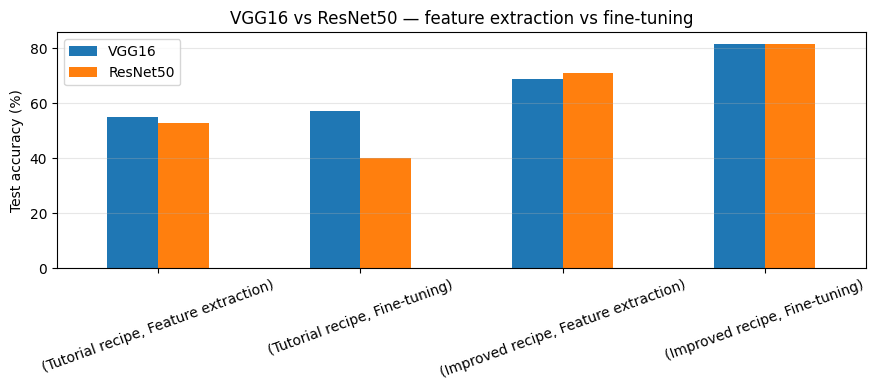

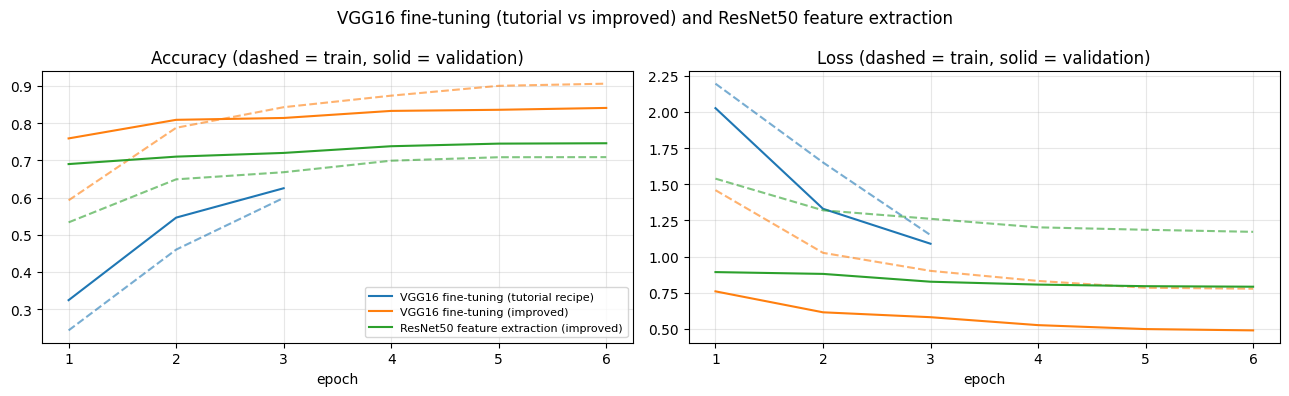

In [ ]:
def acc(r): return round(r["test_acc"] * 100, 2)
grid = pd.DataFrame(
    {("Tutorial recipe", "Feature extraction"): [acc(res_vgg_fe_base), acc(res_r50_fe_tut)],
     ("Tutorial recipe", "Fine-tuning"):        [acc(res_vgg_ft_base), acc(res_r50_ft_base)],
     ("Improved recipe", "Feature extraction"): [acc(res_vgg_fe_imp),  acc(res_r50_fe_imp)],
     ("Improved recipe", "Fine-tuning"):        [acc(res_vgg_ft_imp),  acc(res_r50_ft_imp)]},
    index=["VGG16", "ResNet50"])
print("Test accuracy (%)"); display(grid)

fig, ax = plt.subplots(figsize=(9, 4))
grid.T.plot(kind="bar", ax=ax, rot=20); ax.set_ylabel("Test accuracy (%)"); ax.grid(axis="y", alpha=.3)
ax.set_title("VGG16 vs ResNet50 — feature extraction vs fine-tuning"); plt.tight_layout(); plt.show()
plot_histories([res_vgg_ft_base, res_vgg_ft_imp, res_r50_fe_imp], "VGG16 fine-tuning (tutorial vs improved) and ResNet50 feature extraction")

## Part 5 — Final comparison of every experiment

,name,mode,img_size,trainable_params,test_acc,train_time_s
0,ResNet50 FT S4 + unfreeze more layers,ft,64,23117322,81.7,197
1,VGG16 fine-tuning (improved),ft,64,13772042,81.7,556
2,ResNet50 FT S6 + epochs/cosine/early stop,ft,64,24428810,81.5,388
3,ResNet50 FT S5 + different head layers,ft,64,24428810,78.7,201
4,ResNet50 FT S2 + preprocessing,ft,64,4468234,74.2,100
5,ResNet50 feature extraction [64px],fe,64,1054218,71.2,80
6,VGG16 feature extraction [64px],fe,64,267786,71.0,181
7,ResNet50 feature extraction (improved),fe,64,2365706,70.9,166
8,ResNet50 FT S3 + regularisation,ft,64,4468234,70.8,103
9,VGG16 feature extraction (improved),fe,64,792842,68.8,377


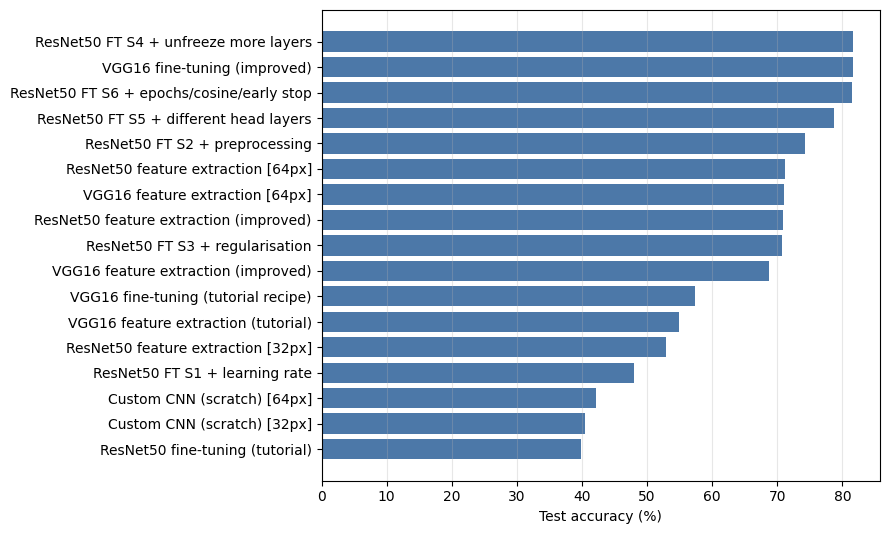

Best model: ResNet50 FT S4 + unfreeze more layers -> 81.70%


In [ ]:
final = results_table(RESULTS).sort_values("test_acc", ascending=False).reset_index(drop=True)
display(final[["name", "mode", "img_size", "trainable_params", "test_acc", "train_time_s"]])
final.to_csv("transfer_learning_results.csv", index=False)

plt.figure(figsize=(9, max(4, 0.32 * len(final))))
plt.barh(final["name"][::-1], final["test_acc"][::-1], color="#4C78A8")
plt.xlabel("Test accuracy (%)"); plt.grid(axis="x", alpha=.3); plt.tight_layout(); plt.show()
print("Best model:", BEST["name"], f"-> {BEST['acc'] * 100:.2f}%")

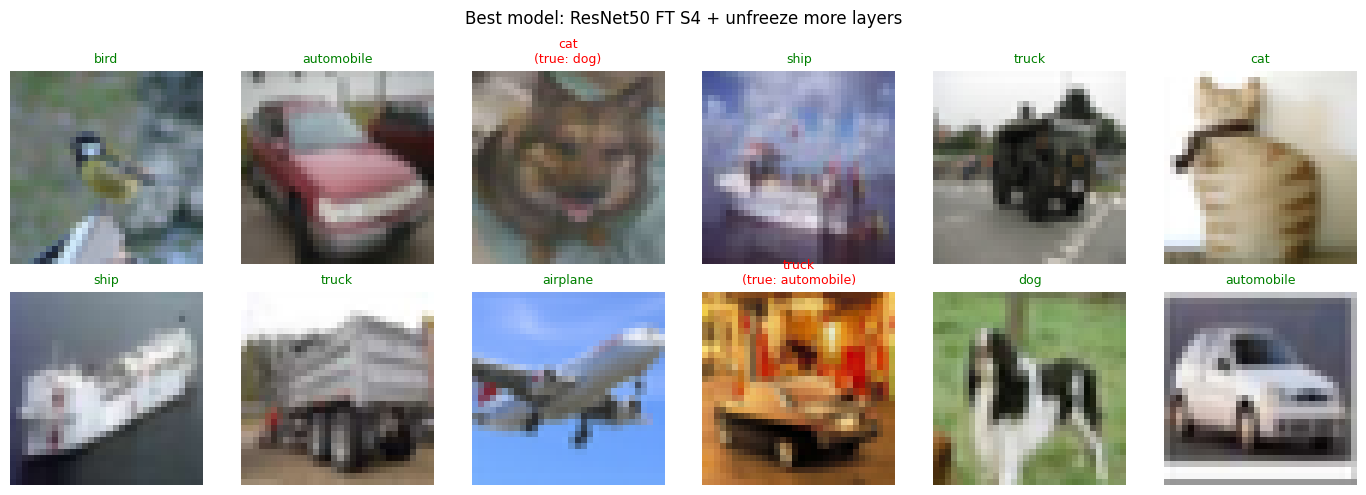

saved best_model.pt


In [ ]:
# Predictions of the best model on a few test images
cfg, model = BEST["cfg"], BEST["model"].to(DEVICE).eval()
raw_test = datasets.CIFAR10(DATA_DIR, train=False, download=False)
_, ev_t = make_transforms(cfg["img_size"], cfg["norm"], False)
idxs = TEST_IDX[:12]
x = torch.stack([ev_t(raw_test[i][0]) for i in idxs]).to(DEVICE)
with torch.no_grad(): pred = model(x).argmax(1).cpu().numpy()
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for ax, i, p in zip(axes.ravel(), idxs, pred):
    img, y = raw_test[i]; ax.imshow(img); ax.axis("off")
    ax.set_title(f"{CLASSES[p]}" + ("" if p == y else f"\n(true: {CLASSES[y]})"), color="green" if p == y else "red", fontsize=9)
plt.suptitle(f"Best model: {BEST['name']}"); plt.tight_layout(); plt.show()

torch.save(model.state_dict(), "best_model.pt"); print("saved best_model.pt")

## Conclusions (compare with *your* numbers above)

**Feature extraction vs fine-tuning.** Feature extraction is cheap (only the head trains) and a strong baseline, but it cannot adapt ImageNet features to the new domain.
Fine-tuning can adapt them, but only if the recipe is right: with the tutorial's `lr = 1e-5`, 32x32 inputs and 5 unfrozen layers it barely moves the weights, which is why it can lose to plain feature extraction.

**How to improve fine-tuning (Part 2).**
1. *Learning rate* — larger LR for the new head (1e-3), small LR for pretrained layers (1e-4); never use a large LR on pretrained layers.
2. *Preprocessing* — ImageNet normalisation and a larger input size (32x32 is far from the 224x224 these networks were trained on).
3. *Prevent overfitting* — augmentation, dropout, weight decay, label smoothing (watch the gap between dashed train and solid validation curves).
4. *Unfreeze more layers* — progressively unfreeze deeper blocks when you have enough data; the more different the new domain, the more layers to unfreeze.
5. *Different layers* — a better head (BatchNorm, deeper MLP, global pooling).
6. *Epochs / early stopping* — train longer with a decaying LR, but stop (and restore the best weights) when validation accuracy stops improving.

**Custom model vs pretrained.** A small CNN from scratch learns from zero and usually needs more epochs/data, while pretrained backbones start from rich features and converge in a few epochs.